# Overnight tests T4-T12: comparison of the results

**notebook version**: `1` (6 Nov 2026)

## ℹ️ About this notebook

Compares the outputs of the test notebooks T4 to T12, run overnight with `run_tests_T4-T12.sh`, with
the product run of the chain (`IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`, `IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`,
run of 4 Nov 2026). Each test changes one setting:

| Test | Notebooks | Change against the product run |
|---|---|---|
| T4, T5, T6 | `IRGA75/T*_01` and `T*_05` | daytime heating part of the opco correction scaled by 0.84, 0.5 and 0 |
| T7, T8 | `IRGA75/T*_05` | random seed 1 and 2 of the gap-filling models (product: 42) |
| T9, T10 | `IRGA72/T*_05` | random seed 1 and 2 of the gap-filling models (product: 42) |
| T11, T12 | `IRGA75/T*_05` | 50 and 200 trees in every gap-filling model (product: chosen by cross-validation, 80) |

The questions:

1. **Heating part by day (T4-T6).** How do the annual `NEE` of the LI-7500 years, its day and night
   parts, `GPP` and `RECO`, and the difference to the LI-7200 in the parallel period change when
   the daytime heating part of opco is reduced? The annual sums are set against the LI-7200 years
   and against Etzold et al. (2011) for 2005-2009.
2. **Noise of the gap-filling models (T7-T10).** How much do the annual sums move with the random
   seed alone?
3. **Number of trees (T11, T12).** How firm are the annual sums against the number of trees?
4. **Order of the USTAR scenarios.** In how many years does `CUT_50` lie outside `CUT_16` to
   `CUT_84` in each run?

For the LI-7500 the product fill `_gfXGWN` (XGBoost with Lloyd-Taylor for the wet nights) is
compared, for the LI-7200 the plain XGBoost fill `_gfXG`, as in the product. A test whose output
file is missing (not run, or failed) is left out and reported.

## ⚙️ Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
STAGE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN'

# Runs: label -> (analyser, output file). 'product' is the run of 4 Nov 2026.
RUNS = {
    'IRGA75 product': ('IRGA75', STAGE / 'IRGA75' / '05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet'),
    'T4 heat day 0.84': ('IRGA75', STAGE / 'IRGA75' / 'T4_05_FPPC_IRGA75_NEE_OPCO_HEATDAY084_2004-2017.parquet'),
    'T5 heat day 0.5': ('IRGA75', STAGE / 'IRGA75' / 'T5_05_FPPC_IRGA75_NEE_OPCO_HEATDAY050_2004-2017.parquet'),
    'T6 heat day 0': ('IRGA75', STAGE / 'IRGA75' / 'T6_05_FPPC_IRGA75_NEE_OPCO_HEATDAY000_2004-2017.parquet'),
    'T7 seed 1': ('IRGA75', STAGE / 'IRGA75' / 'T7_05_FPPC_IRGA75_NEE_OPCO_SEED1_2004-2017.parquet'),
    'T8 seed 2': ('IRGA75', STAGE / 'IRGA75' / 'T8_05_FPPC_IRGA75_NEE_OPCO_SEED2_2004-2017.parquet'),
    'T11 50 trees': ('IRGA75', STAGE / 'IRGA75' / 'T11_05_FPPC_IRGA75_NEE_OPCO_TREES50_2004-2017.parquet'),
    'T12 200 trees': ('IRGA75', STAGE / 'IRGA75' / 'T12_05_FPPC_IRGA75_NEE_OPCO_TREES200_2004-2017.parquet'),
    'IRGA72 product': ('IRGA72', STAGE / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet'),
    'T9 seed 1 (IRGA72)': ('IRGA72', STAGE / 'IRGA72' / 'T9_05_FPPC_IRGA72_NEE_SEED1_2016-2026.09.parquet'),
    'T10 seed 2 (IRGA72)': ('IRGA72', STAGE / 'IRGA72' / 'T10_05_FPPC_IRGA72_NEE_SEED2_2016-2026.09.parquet'),
}
HEAT_RUNS = {'IRGA75 product': 1.0, 'T4 heat day 0.84': 0.84, 'T5 heat day 0.5': 0.5, 'T6 heat day 0': 0.0}
SEED_RUNS = {'IRGA75': ['IRGA75 product', 'T7 seed 1', 'T8 seed 2'],
             'IRGA72': ['IRGA72 product', 'T9 seed 1 (IRGA72)', 'T10 seed 2 (IRGA72)']}
TREE_RUNS = {'IRGA75 product': 'CV (80)', 'T11 50 trees': '50', 'T12 200 trees': '200'}

# The fill of the product: LI-7500 with Lloyd-Taylor for the wet nights, LI-7200 plain XGBoost.
FILL = {'IRGA75': '_gfXGWN', 'IRGA72': '_gfXG'}
SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']
YEARS = {'IRGA75': range(2004, 2018), 'IRGA72': range(2016, 2026)}  # complete years of each record
PERIODS = {'2004-2006': (2004, 2006), '2007-2009': (2007, 2009), '2010-2015': (2010, 2015),
           '2005-2009': (2005, 2009)}
REF_YEARS = (2016, 2025)  # LI-7200 years, the reference
PARALLEL = ('2016-01-11', '2017-12-12')  # both analysers measured
DT_FIRST_YEAR = 2006  # first complete year of the daytime partitioning (from 14 Sep 2005)

# Etzold et al. (2011), mean annual NEE 2005-2009 and its range (p. 1301 and Table 4), as declared in
# 90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.
ETZOLD_YEARS = (2005, 2009)
ETZOLD_MEAN = -415
ETZOLD_RANGE = (-662, -366)

UMOL_TO_GC = 12.011e-6 * 1800  # umol m-2 s-1 over a half-hour -> gC m-2

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)


def tabcap(text, width=110):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-06 23:59:44


## 📂 Load data

In [3]:
def columns(analyser):
    fill = FILL[analyser]
    cols = [f'NEE_L3.1_L3.3_{s}_QCF{fill}' for s in SCENARIOS] + ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS',
            'NEE_L3.1_L3.3_CUT_50_QCF', 'DAYTIME', 'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50',
            'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50']
    return cols


DATA, MISSING = {}, []
for label, (analyser, path) in RUNS.items():
    if not path.is_file():
        MISSING.append(label)
        continue
    df = pd.read_parquet(path, columns=columns(analyser))
    df.index = pd.DatetimeIndex(df.index)
    # Short names: NEE per scenario with the product fill, and the rest as they are.
    df = df.rename(columns={f'NEE_L3.1_L3.3_{s}_QCF{FILL[analyser]}': s for s in SCENARIOS})
    assert not df.index.duplicated().any(), f"{label}: duplicate timestamps"
    DATA[label] = df
    print(f"{label}: {path.name}, modified {datetime.fromtimestamp(path.stat().st_mtime):%Y-%m-%d %H:%M}")
print(f"\nmissing (not run or failed): {MISSING if MISSING else 'none'}")
assert 'IRGA75 product' in DATA and 'IRGA72 product' in DATA, "a product run is missing"


def annual(label, col='CUT_50', mask=None):
    """Annual sums (gC m-2) of one column over the complete years of the run's analyser."""
    df = DATA[label]
    s = df[col] if mask is None else df[col].where(mask(df), 0.0)
    years = YEARS[RUNS[label][0]]
    return (s.groupby(df.index.year).sum() * UMOL_TO_GC).reindex(years)


def period_mean(series, period):
    lo, hi = PERIODS[period] if isinstance(period, str) else period
    return series.loc[lo:hi].mean()


REF = annual('IRGA72 product')
REF_MEAN = period_mean(REF, REF_YEARS)
print(f"LI-7200 mean annual NEE {REF_YEARS[0]}-{REF_YEARS[1]} (CUT_50): {REF_MEAN:.0f} gC m-2")

IRGA75 product: 05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet, modified 2026-11-04 16:40


T4 heat day 0.84: T4_05_FPPC_IRGA75_NEE_OPCO_HEATDAY084_2004-2017.parquet, modified 2026-11-06 19:11


T5 heat day 0.5: T5_05_FPPC_IRGA75_NEE_OPCO_HEATDAY050_2004-2017.parquet, modified 2026-11-06 20:03
T6 heat day 0: T6_05_FPPC_IRGA75_NEE_OPCO_HEATDAY000_2004-2017.parquet, modified 2026-11-06 20:56
T7 seed 1: T7_05_FPPC_IRGA75_NEE_OPCO_SEED1_2004-2017.parquet, modified 2026-11-06 21:46
T8 seed 2: T8_05_FPPC_IRGA75_NEE_OPCO_SEED2_2004-2017.parquet, modified 2026-11-06 22:35
T11 50 trees: T11_05_FPPC_IRGA75_NEE_OPCO_TREES50_2004-2017.parquet, modified 2026-11-06 23:34
T12 200 trees: T12_05_FPPC_IRGA75_NEE_OPCO_TREES200_2004-2017.parquet, modified 2026-11-06 23:59


IRGA72 product: 05_FPPC_IRGA72_NEE_2016-2026.09.parquet, modified 2026-11-04 15:46
T9 seed 1 (IRGA72): T9_05_FPPC_IRGA72_NEE_SEED1_2016-2026.09.parquet, modified 2026-11-06 22:56
T10 seed 2 (IRGA72): T10_05_FPPC_IRGA72_NEE_SEED2_2016-2026.09.parquet, modified 2026-11-06 23:17

missing (not run or failed): none
LI-7200 mean annual NEE 2016-2025 (CUT_50): -23 gC m-2


## 1. Heating part of opco by day (T4-T6)

### 📋 Table: annual NEE of the LI-7500 at each daytime scale of the heating part

In [4]:
HEAT = {s: annual(lbl) for lbl, s in HEAT_RUNS.items() if lbl in DATA}
heat_annual = pd.DataFrame(HEAT)
heat_annual.columns = [f"scale {s:g}" for s in heat_annual.columns]
heat_annual.index.name = 'year'
tabcap("annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 for each scale of the daytime heating "
       "part of the opco correction; scale 1 is the product run")
display(heat_annual.round(0))

Table - annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 for each scale of the daytime heating part of
the opco correction; scale 1 is the product run



,scale 1,scale 0.84,scale 0.5,scale 0
year,,,,
2004,248.0,136.0,-72.0,-372.0
2005,275.0,183.0,-4.0,-301.0
2006,457.0,368.0,191.0,-88.0
2007,123.0,45.0,-107.0,-354.0
2008,143.0,57.0,-116.0,-397.0
2009,91.0,12.0,-172.0,-451.0
2010,33.0,-59.0,-261.0,-541.0
2011,8.0,-94.0,-274.0,-541.0
2012,-36.0,-103.0,-274.0,-577.0


### 📋 Table: period means against the LI-7200 years and Etzold et al. (2011)

In [5]:
_rows = {}
for col in heat_annual.columns:
    s = heat_annual[col]
    _r = {p: period_mean(s, p) for p in PERIODS}
    _r.update({f"{p} minus LI-7200": period_mean(s, p) - REF_MEAN for p in ('2004-2006', '2007-2009', '2010-2015')})
    _r['2005-2009 minus Etzold et al.'] = period_mean(s, ETZOLD_YEARS) - ETZOLD_MEAN
    _rows[col] = _r
heat_periods = pd.DataFrame(_rows).T
tabcap(f"mean annual NEE (gC m-2) per period for each scale, its difference to the LI-7200 mean of "
       f"{REF_YEARS[0]}-{REF_YEARS[1]} ({REF_MEAN:.0f}) and to the mean of Etzold et al. (2011) for 2005-2009 "
       f"({ETZOLD_MEAN}, range {ETZOLD_RANGE[0]} to {ETZOLD_RANGE[1]})")
display(heat_periods.round(0))

Table - mean annual NEE (gC m-2) per period for each scale, its difference to the LI-7200 mean of 2016-2025
(-23) and to the mean of Etzold et al. (2011) for 2005-2009 (-415, range -662 to -366)



,2004-2006,2007-2009,2010-2015,2005-2009,2004-2006 minus LI-7200,2007-2009 minus LI-7200,2010-2015 minus LI-7200,2005-2009 minus Etzold et al.
scale 1,327.0,119.0,-8.0,218.0,349.0,142.0,15.0,633.0
scale 0.84,229.0,38.0,-95.0,133.0,251.0,61.0,-72.0,548.0
scale 0.5,38.0,-132.0,-281.0,-42.0,61.0,-109.0,-258.0,373.0
scale 0,-254.0,-401.0,-578.0,-318.0,-231.0,-378.0,-556.0,97.0


### 📋 Table: day and night parts of the period means

In [6]:
_rows = {}
for lbl, s in HEAT_RUNS.items():
    if lbl not in DATA:
        continue
    day = annual(lbl, mask=lambda d: d['DAYTIME'] == 1)
    night = annual(lbl, mask=lambda d: d['DAYTIME'] != 1)
    for p in ('2004-2006', '2007-2009', '2010-2015'):
        _rows[(f"scale {s:g}", p)] = {'day': period_mean(day, p), 'night': period_mean(night, p)}
_ref_day = period_mean(annual('IRGA72 product', mask=lambda d: d['DAYTIME'] == 1), REF_YEARS)
_ref_night = period_mean(annual('IRGA72 product', mask=lambda d: d['DAYTIME'] != 1), REF_YEARS)
heat_daynight = pd.DataFrame(_rows).T
heat_daynight['day minus LI-7200'] = heat_daynight['day'] - _ref_day
heat_daynight['night minus LI-7200'] = heat_daynight['night'] - _ref_night
tabcap(f"mean annual NEE (gC m-2) by day and by night (DAYTIME flag) per period and scale, and the "
       f"differences to the LI-7200 years (day {_ref_day:.0f}, night {_ref_night:.0f})")
display(heat_daynight.round(0))

Table - mean annual NEE (gC m-2) by day and by night (DAYTIME flag) per period and scale, and the differences
to the LI-7200 years (day -874, night 851)



day  night  day minus LI-7200  night minus LI-7200
scale 1    2004-2006  -435.0  762.0              439.0                -89.0
           2007-2009  -651.0  770.0              223.0                -81.0
           2010-2015  -788.0  780.0               86.0                -71.0
scale 0.84 2004-2006  -530.0  758.0              344.0                -93.0
           2007-2009  -734.0  772.0              140.0                -79.0
           2010-2015  -874.0  779.0               -0.0                -72.0
scale 0.5  2004-2006  -717.0  756.0              157.0                -96.0
           2007-2009  -904.0  772.0              -30.0                -79.0
           2010-2015 -1064.0  783.0             -190.0                -68.0
scale 0    2004-2006  -989.0  735.0             -115.0               -116.0
           2007-2009 -1163.0  762.0             -288.0                -90.0
           2010-2015 -1351.0  773.0             -477.0                -79.0

### 📋 Table: partitioning per period

In [7]:
_rows = {}
for lbl, s in HEAT_RUNS.items():
    if lbl not in DATA:
        continue
    for p in ('2004-2006', '2007-2009', '2010-2015'):
        _r = {c: period_mean(annual(lbl, c), p) for c in ('GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50')}
        lo, hi = PERIODS[p]
        _r.update({c: period_mean(annual(lbl, c), (max(lo, DT_FIRST_YEAR), hi))
                   for c in ('GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50')})
        _rows[(f"scale {s:g}", p)] = _r
_rows[('LI-7200', f"{REF_YEARS[0]}-{REF_YEARS[1]}")] = {
    c: period_mean(annual('IRGA72 product', c), REF_YEARS)
    for c in ('GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50', 'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50')}
heat_part = pd.DataFrame(_rows).T
tabcap(f"mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period "
       f"and scale; the daytime method from {DT_FIRST_YEAR}, its first complete year")
display(heat_part.round(0))

Table - mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period and
scale; the daytime method from 2006, its first complete year



GPP_NT_OF_CUT_50  RECO_NT_OF_CUT_50  GPP_DT_OF_CUT_50  RECO_DT_OF_CUT_50
scale 1    2004-2006            1179.0             1505.0            1190.0             1778.0
           2007-2009            1532.0             1651.0            1510.0             1857.0
           2010-2015            1621.0             1612.0            1575.0             1786.0
scale 0.84 2004-2006            1274.0             1502.0            1245.0             1753.0
           2007-2009            1614.0             1652.0            1569.0             1809.0
           2010-2015            1710.0             1615.0            1653.0             1777.0
scale 0.5  2004-2006            1459.0             1497.0            1466.0             1851.0
           2007-2009            1780.0             1648.0            1709.0             1815.0
           2010-2015            1894.0             1612.0            1808.0             1792.0
scale 0    2004-2006            1739.0             1485.0            1650.0             1856.0
           2007-2009            2050.0             1649.0            1932.0             1888.0
           2010-2015            2192.0             1613.0            2018.0             1752.0
LI-7200    2016-2025            1885.0             1863.0            2071.0             2241.0

### 📋 Table: LI-7500 minus LI-7200 in the parallel period

In [8]:
_p = slice(*PARALLEL)
_ref = DATA['IRGA72 product'].loc[_p]
_rows = {}
for lbl, s in HEAT_RUNS.items():
    if lbl not in DATA:
        continue
    _d = DATA[lbl].loc[_p]
    _diff = (_d['CUT_50'] - _ref['CUT_50'].reindex(_d.index)) * UMOL_TO_GC
    _day = _d['DAYTIME'] == 1
    _both = _d['NEE_L3.1_L3.3_CUT_50_QCF'].notna() & _ref['NEE_L3.1_L3.3_CUT_50_QCF'].reindex(_d.index).notna()
    _rows[f"scale {s:g}"] = {'all half-hours': _diff.sum(), 'day': _diff[_day].sum(), 'night': _diff[~_day].sum(),
                             'measured by both': _diff[_both].sum()}
heat_parallel = pd.DataFrame(_rows).T
tabcap(f"sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, each with its product fill) over the parallel "
       f"period {PARALLEL[0]} to {PARALLEL[1]}: all half-hours, by day and by night, and on the half-hours "
       f"both analysers measured. Negative: the LI-7500 shows more uptake")
display(heat_parallel.round(0))

Table - sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, each with its product fill) over the parallel period
2016-01-11 to 2017-12-12: all half-hours, by day and by night, and on the half-hours both analysers measured.
Negative: the LI-7500 shows more uptake



,all half-hours,day,night,measured by both
scale 1,-407.0,-106.0,-301.0,-5.0
scale 0.84,-593.0,-286.0,-307.0,-48.0
scale 0.5,-898.0,-606.0,-293.0,-133.0
scale 0,-1441.0,-1135.0,-305.0,-263.0


### 📊 Plot: annual NEE of the LI-7500 at each daytime scale

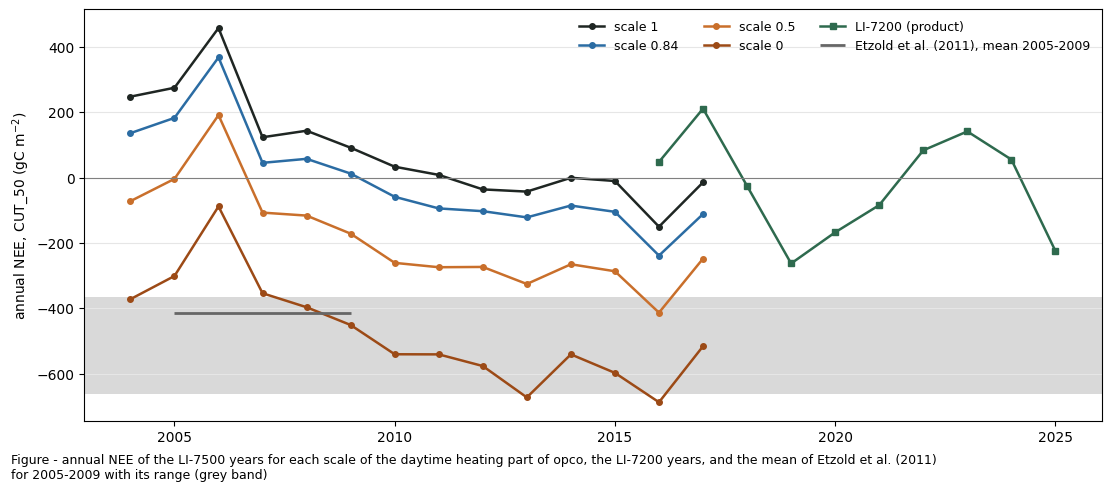

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
_colors = {1.0: '#1F2623', 0.84: '#2B6CA3', 0.5: '#C96F2B', 0.0: '#9C4A16'}
for lbl, s in HEAT_RUNS.items():
    if lbl in DATA:
        _a = annual(lbl)
        ax.plot(_a.index, _a, marker='o', ms=4, lw=1.8, color=_colors[s], label=f"scale {s:g}")
ax.plot(REF.index, REF, marker='s', ms=4, lw=1.8, color='#2E6A4E', label='LI-7200 (product)')
ax.axhspan(*ETZOLD_RANGE, xmin=0, xmax=1, color='0.85', lw=0, zorder=0)
ax.hlines(ETZOLD_MEAN, *ETZOLD_YEARS, color='0.4', lw=2, label='Etzold et al. (2011), mean 2005-2009')
ax.axhline(0, color='0.5', lw=0.8)
ax.set_ylabel('annual NEE, CUT_50 (gC m$^{-2}$)')
ax.legend(frameon=False, fontsize=9, ncol=3)
ax.grid(axis='y', color='0.9')
figcap(fig, "annual NEE of the LI-7500 years for each scale of the daytime heating part of opco, the "
            "LI-7200 years, and the mean of Etzold et al. (2011) for 2005-2009 with its range (grey band)")
plt.show()

## 2. Noise of the gap-filling models (T7-T10)

### 📋 Table: annual NEE per random seed

In [10]:
_tabs = {}
for analyser, labels in SEED_RUNS.items():
    _have = [l for l in labels if l in DATA]
    _t = pd.DataFrame({l: annual(l) for l in _have})
    if len(_have) > 1:
        _t['max - min'] = _t[_have].max(axis=1) - _t[_have].min(axis=1)
        _t['SD'] = _t[_have].std(axis=1)
    _tabs[analyser] = _t
    _t.index.name = 'year'
    tabcap(f"{analyser}: annual NEE (gC m-2, CUT_50, product fill) for the random seed of the product (42) "
           f"and the test seeds, with the spread between them")
    display(_t.round(0))

Table - IRGA75: annual NEE (gC m-2, CUT_50, product fill) for the random seed of the product (42) and the test
seeds, with the spread between them



,IRGA75 product,T7 seed 1,T8 seed 2,max - min,SD
year,,,,,
2004,248.0,249.0,257.0,10.0,5.0
2005,275.0,278.0,276.0,3.0,2.0
2006,457.0,459.0,450.0,9.0,5.0
2007,123.0,128.0,120.0,9.0,4.0
2008,143.0,143.0,139.0,4.0,2.0
2009,91.0,97.0,94.0,6.0,3.0
2010,33.0,35.0,30.0,4.0,2.0
2011,8.0,11.0,7.0,4.0,2.0
2012,-36.0,-36.0,-40.0,4.0,2.0


Table - IRGA72: annual NEE (gC m-2, CUT_50, product fill) for the random seed of the product (42) and the test
seeds, with the spread between them



,IRGA72 product,T9 seed 1 (IRGA72),T10 seed 2 (IRGA72),max - min,SD
year,,,,,
2016,48.0,98.0,62.0,51.0,26.0
2017,211.0,192.0,188.0,23.0,12.0
2018,-26.0,-35.0,-28.0,9.0,5.0
2019,-263.0,-267.0,-261.0,6.0,3.0
2020,-168.0,-174.0,-169.0,7.0,3.0
2021,-84.0,-95.0,-104.0,20.0,10.0
2022,83.0,81.0,72.0,11.0,6.0
2023,141.0,134.0,134.0,7.0,4.0
2024,55.0,64.0,55.0,9.0,5.0


### 📋 Table: spread of the seeds in the period means

In [11]:
_rows = {}
for analyser, labels in SEED_RUNS.items():
    _have = [l for l in labels if l in DATA]
    periods = ({'2004-2006': (2004, 2006), '2010-2015': (2010, 2015), '2016-2017': (2016, 2017)}
               if analyser == 'IRGA75' else {'2016-2025': REF_YEARS})
    for p, (lo, hi) in periods.items():
        _m = {l: annual(l).loc[lo:hi].mean() for l in _have}
        _rows[(analyser, p)] = {**_m, 'max - min': max(_m.values()) - min(_m.values())} if _m else {}
seed_periods = pd.DataFrame(_rows).T
tabcap("mean annual NEE (gC m-2) per period for each seed, and the spread between the seeds")
display(seed_periods.round(0))

Table - mean annual NEE (gC m-2) per period for each seed, and the spread between the seeds



IRGA75 product  T7 seed 1  T8 seed 2  max - min  IRGA72 product  T9 seed 1 (IRGA72)  T10 seed 2 (IRGA72)
IRGA75 2004-2006           327.0      329.0      328.0        2.0             NaN                 NaN                  NaN
       2010-2015            -8.0       -8.0      -11.0        3.0             NaN                 NaN                  NaN
       2016-2017           -83.0      -81.0      -80.0        2.0             NaN                 NaN                  NaN
IRGA72 2016-2025             NaN        NaN        NaN        5.0           -23.0               -23.0                -27.0

## 3. Number of trees (T11, T12)

### 📋 Table: annual NEE of the LI-7500 per number of trees

In [12]:
_have = [l for l in TREE_RUNS if l in DATA]
tree_annual = pd.DataFrame({TREE_RUNS[l]: annual(l) for l in _have})
tree_annual['XGBoost minus MDS (product)'] = annual('IRGA75 product') - annual('IRGA75 product', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS')
tree_annual.index.name = 'year'
tabcap("annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 for the number of trees chosen by "
       "cross-validation (product) and for 50 and 200 trees, and the product's XGBoost minus MDS")
display(tree_annual.round(0))

Table - annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 for the number of trees chosen by cross-
validation (product) and for 50 and 200 trees, and the product's XGBoost minus MDS



,CV (80),50,200,XGBoost minus MDS (product)
year,,,,
2004,248.0,215.0,281.0,238.0
2005,275.0,237.0,288.0,88.0
2006,457.0,403.0,494.0,-61.0
2007,123.0,100.0,116.0,37.0
2008,143.0,97.0,154.0,22.0
2009,91.0,33.0,133.0,-42.0
2010,33.0,-3.0,39.0,41.0
2011,8.0,-25.0,3.0,137.0
2012,-36.0,-56.0,-23.0,150.0


## 4. Order of the USTAR scenarios

### 📋 Table: years in which CUT_50 lies outside CUT_16 to CUT_84

In [13]:
_rows = {}
for lbl in DATA:
    _a = pd.DataFrame({s: annual(lbl, s) for s in SCENARIOS})
    _lo, _hi = _a[['CUT_16', 'CUT_84']].min(axis=1), _a[['CUT_16', 'CUT_84']].max(axis=1)
    _out = _a.index[(_a['CUT_50'] < _lo) | (_a['CUT_50'] > _hi)]
    _rows[lbl] = {'years': len(_a), 'outside': len(_out), 'which': ', '.join(str(y) for y in _out)}
order = pd.DataFrame(_rows).T
tabcap("per run, the number of complete years in which the annual CUT_50 sum lies outside the range of "
       "CUT_16 and CUT_84 (product fill)")
display(order)

Table - per run, the number of complete years in which the annual CUT_50 sum lies outside the range of CUT_16
and CUT_84 (product fill)



,years,outside,which
IRGA75 product,14,1,2006
T4 heat day 0.84,14,1,2006
T5 heat day 0.5,14,0,
T6 heat day 0,14,2,"2004, 2006"
T7 seed 1,14,1,2006
T8 seed 2,14,1,2006
T11 50 trees,14,1,2006
T12 200 trees,14,1,2006
IRGA72 product,10,1,2017
T9 seed 1 (IRGA72),10,1,2017


## ⏱️ Runtime

In [14]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-06 23:59:48, runtime 0:00:03.285385
